# IHLT Project
Students : Oscar Cubeles, Valentin-Gabriel Soumah

Description of the Project and Notebook ...

In [1]:
import os
import importlib
# NLP Libraries
from load_data import load_files, merge_datasets 
import preprocessing as pp

# ML Libraries
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge

from numpy import corrcoef
import pandas as pd
import numpy as np

import spacy
nlp = spacy.load("en_core_web_md")



import numpy as np
import pandas as pd
from scipy.stats import pearsonr

import features as ft
import feature_selection as fs
importlib.reload(ft)
importlib.reload(pp)

import matplotlib.pyplot as plt

# TODO
# Divide features between lexical and syntactic
# Train more models and check which works best on train set
# Add more features or change/revise current ones (?)
# Make feature selection


## 1) Data Preparation

### Loading Data

In [2]:
data_path = 'data/train/train/'
df_paraphrases = load_files(data_path+'STS.gs.MSRpar.txt', data_path+'STS.input.MSRpar.txt')
df_vid = load_files(data_path+'STS.gs.MSRvid.txt', data_path+'STS.input.MSRvid.txt')
df_europarl = load_files(data_path+'STS.gs.SMTeuroparl.txt', data_path+'STS.input.SMTeuroparl.txt') 

In [3]:
df = merge_datasets([df_paraphrases, df_vid , df_europarl])
df

,sentence1,sentence2,score
0,But other sources close to the sale said Viven...,But other sources close to the sale said Viven...,4.00
1,Micron has declared its first quarterly profit...,Micron's numbers also marked the first quarter...,3.75
2,The fines are part of failed Republican effort...,"Perry said he backs the Senate's efforts, incl...",2.80
3,"The American Anglican Council, which represent...","The American Anglican Council, which represent...",3.40
4,The tech-loaded Nasdaq composite rose 20.96 po...,The technology-laced Nasdaq Composite Index <....,2.40
...,...,...,...
2229,"Action is needed quickly, which is why we deci...",It is urgent and that is why we have decided t...,5.00
2230,One could indeed wish for more and for improve...,"We can actually want more and better, but I th...",4.80
2231,(Parliament accepted the oral amendment),(Parliament accepted the oral amendment),5.00
2232,- My party has serious reservations about Comm...,My party serious reservations about the regula...,4.80


### Preprocessing
1. All hyphens and slashes are removed;
2. The angular brackets (< and >) that enclose the
tokens are stripped (simple);
3. The currency values are simplified, e.g.,
$US1234 to $1234 (simple);
5. The tokens n’t and ’m are replaced with not and
am, respectively (simple);
6. The two consecutive words in one sentence that
appear as a compound in the other sentence are
replaced by the said compound. E.g., cater pillar in one sentence is replaced with caterpillar only if caterpillar appears in the other sentence;

In [4]:
df_preprocessed = pp.preprocess_dataframe(df)
df_preprocessed.head(15)
print(df_preprocessed.iloc[11]["sentence1"])

Replacements were made:
Before: Chavez said investigators feel confident they've got "at least one of the fires resolved in that regard."
After:  Chavez said investigators feel confident they have got "at least one of the fires resolved in that regard."
Replacements were made:
Before: Plofsky said the commission won't investigate because the three year statute of limitations has expired.
After:  Plofsky said the commission will not investigate because the three year statute of limitations has expired.
Replacements were made:
Before: In two weeks, he'll probably send out Peace Rules in the Preakness.
After:  In two weeks, he will probably send out Peace Rules in the Preakness.
Replacements were made:
Before: Still, he said, "I'm absolutely confident we're going to have a bill."
After:  Still, he said, "I am absolutely confident we are going to have a bill."
Replacements were made:
Before: "I'm absolutely confident we're going to have a bill," Frist, R Tenn., said Thursday.
After:  "I am

### Generating Features

In [5]:

match_based_features = [ 
            ft.word_jaccard_distance, 
            ft.compute_number_similarity,
            ft.date_similarity,
            ft.word_bigram_jaccard, 
            ft.word_trigram_jaccard,
]
lexical_features = [ft.synset_jaccard_distance,
            ft.weighted_wordnet_similarity,
            ft.sentence_path_similarity,
            ft.sentence_lch_similarity,
            ft.sentence_wup_similarity,
            ft.sentence_lin_similarity,
            ft.sentence_path_similarity_max,
            ft.sentence_lch_similarity_max,
            ft.sentence_wup_similarity_max,
            ft.sentence_lin_similarity_max,
            ft.sentence_rarity_similarity,
            ft.stem_jaccard_distance,
            ft.lemma_jaccard_distance,
            ft.lemma_bigram_jaccard, 
            ft.lemma_trigram_jaccard,

            #ft.dt_number_similarity, # this one we can't use because it uses word vectors]
]
syntactic_features = [ft.pos_jaccard_distance,
            ft.sentence_length_difference,
            ft.longest_common_subsequence, 
            ft.longest_common_substring,
            ft.greedy_string_tiling,
            ft.pos_lev_distance,
            ft.dep_lev_distance,
            ft.ner_jaccard,
            ft.ner_presence,

            ]

features = match_based_features  + lexical_features + syntactic_features
match_based_features_names = [func.__name__ for func in match_based_features]
lexical_match_features_names = [func.__name__ for func in lexical_features] + match_based_features_names
syntactic_match_features_names = [func.__name__ for func in syntactic_features] + match_based_features_names

We have designed X features. Those features have been divided into 3 categories : 
- Match-based features. Those features do not rely on any external resources nor annotations, they are computed purely based on the immediate form of the sentences and their tokens. <br> 
LIST AND DESCRIBE THE FEATURES
- Lexical Features. Those features leverage external lexical ressources (wordnet or more basic lexicons for lemmatization) <br>
LIST AND DESCRIBE THE FEATURES
- syntactic features. Those feature harness the annotations made by NLP annotation tools (parsing, pos-tagging etc). In our case, all the annotations are provided by spacy NLP pipeline. <br>
LIST AND DESCRIBE THE FEATURES

In [6]:
X_raw = ft.compute_features(df_preprocessed, features, feature_dir='data/features_train')
y = df_preprocessed['score']
X_raw.head(), y.head()


preparing spacy analysis...
Loading cached feature: data/features_train/word_jaccard_distance.csv
Loading cached feature: data/features_train/compute_number_similarity.csv
Loading cached feature: data/features_train/date_similarity.csv
Loading cached feature: data/features_train/word_bigram_jaccard.csv
Loading cached feature: data/features_train/word_trigram_jaccard.csv
Loading cached feature: data/features_train/synset_jaccard_distance.csv
Loading cached feature: data/features_train/weighted_wordnet_similarity.csv
Loading cached feature: data/features_train/sentence_path_similarity.csv
Loading cached feature: data/features_train/sentence_lch_similarity.csv
Loading cached feature: data/features_train/sentence_wup_similarity.csv
Loading cached feature: data/features_train/sentence_lin_similarity.csv
Loading cached feature: data/features_train/sentence_path_similarity_max.csv
Loading cached feature: data/features_train/sentence_lch_similarity_max.csv
Loading cached feature: data/features

(   word_jaccard_distance  compute_number_similarity  date_similarity  \
 0               0.437500                        0.0              0.0   
 1               0.555556                        1.0              0.0   
 2               0.615385                        0.0              0.0   
 3               0.352941                        0.0              0.0   
 4               0.863636                        0.0              0.0   
 
    word_bigram_jaccard  word_trigram_jaccard  synset_jaccard_distance  \
 0             0.210526              0.105263                 0.736842   
 1             0.000000              0.000000                 0.636364   
 2             0.066667              0.000000                 0.615385   
 3             0.300000              0.142857                 0.550000   
 4             0.045455              0.000000                 0.933333   
 
    weighted_wordnet_similarity  sentence_path_similarity  \
 0                     0.631071                  0.68

In [7]:
s1 = nlp("The quantum trial was decent  January 1 2025, February 1 2025")
s2 = nlp("This quantum experiment is cool 01/01/2025")

s3 = nlp("The experiment is in January 1, 2025 years old") # may be added to the preprocessing too. 
s4 = nlp("This is a quantum 01/01/2025  years of age")


print(ft.date_similarity(s1, s2))
print(ft.weighted_wordnet_similarity(s1, s2))
print(ft.sentence_rarity_similarity(s1, s2, power=4))
print(1-ft.word_jaccard_distance(s1, s2))
print(ft.sentence_length_difference(s1, s2))
print(ft.compute_number_similarity(s3, s4))

1.0
0.10379319694020639
0.1156832009671052
0.09090909090909094
0.45454545454545453
1.0


Normalization. We keep the scaler to transform the test set later.

In [8]:
# Scale features
scaler = MinMaxScaler()
X = pd.DataFrame(scaler.fit_transform(X_raw), columns=X_raw.columns)


We split the data into train and val. Train will be used for training and cross validation (see below), while val will be used to assess the generalization ability of the selected models.

In [9]:
# Split data
X_train, X_val, y_train, y_val, df_preprocessed_train, df_preprocessed_val = train_test_split(
    X, y, df_preprocessed,  test_size=0.1, random_state=42
)

## 2) Model Selection : baselines

In this section, we evaluate three regression algorithms as initial baselines for our prediction task: Ridge Regression, Random Forest Regression, and Support Vector Regression (SVR). These models were selected because they offer complementary advantages in terms of interpretability, robustness, and modeling capacity.

`Ridge Regression` serves as our most basic linear baseline. Its main strength lies in its interpretability: the learned coefficients provide immediate insight into the influence of each feature. Ridge is also computationally lightweight and offers a simple reference point against which more complex models can be compared.

`Random Forest Regression` is included because it naturally captures non-linear interactions between features, is robust to noise, and provides reliable permutation-based feature importance. This makes it a strong general-purpose model and a natural candidate for evaluating which features contribute the most.

`Support Vector Regression (SVR)` is a classic, high-performing model known for its ability to produce strong results without extensive fine-tuning. SVR often performs well on medium-sized datasets, making it a natural choice in our context as a stable, widely-used machine learning baseline.

For all three models, we apply grid-search hyperparameter tuning combined with 5-fold cross-validation. This ensures:

- fair comparison across models,
- robust performance estimates,
- meaningful insight into how each model behaves when using all available features.

The goal of this section is to establish initial benchmark performances and identify which model families are most promising before moving to deeper feature analysis and selection.

In [11]:

def pearson_corr(model, X_val, y_val):
    preds = model.predict(X_val)
    return preds, pearsonr(y_val, preds)[0]

# Ridge Regression
# ------------
ridge_param_grid = {
    "alpha": [0.01, 0.1, 1, 10, 100],
    "fit_intercept": [True, False],
    "solver": ["auto", "svd", "cholesky", "lsqr"],
}

ridge_gs = GridSearchCV(
    Ridge(random_state=42),
    ridge_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=0
)

ridge_gs.fit(X_train, y_train)
best_ridge_all = ridge_gs.best_estimator_
_, corr_ridge_all = pearson_corr(best_ridge_all, X_val, y_val)

print("Ridge Best Params:", ridge_gs.best_params_)
print("Ridge Pearson Corr on Validation:", corr_ridge_all)



# Random Forest Regression
# -----------
rf_param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [5, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}

rf_gs = GridSearchCV(
    RandomForestRegressor(random_state=42),
    rf_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=0
)

rf_gs.fit(X_train, y_train)
best_rf_all = rf_gs.best_estimator_
_, corr_rf_all = pearson_corr(best_rf_all, X_val, y_val)

print("Random Forest Best Params:", rf_gs.best_params_)
print("Random Forest Pearson Corr on Validation:", corr_rf_all)


# Support Vector Regression (SVR)
# -------------------------------
svr_param_grid = {
    "C": [0.1, 1, 10],
    "epsilon": [0.01, 0.1],
    "kernel": ["rbf"],
    "gamma": ["scale", "auto"]
}

svr_gs = GridSearchCV(
    SVR(),
    svr_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=0
)

svr_gs.fit(X_train, y_train)
best_svr_all = svr_gs.best_estimator_
_, corr_svr_all = pearson_corr(best_svr_all, X_val, y_val)

print("SVR Best Params:", svr_gs.best_params_)
print("SVR Pearson Corr on Validation:", corr_svr_all)


Ridge Best Params: {'alpha': 0.1, 'fit_intercept': False, 'solver': 'svd'}
Ridge Pearson Corr on Validation: 0.7671703475478384
Random Forest Best Params: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Random Forest Pearson Corr on Validation: 0.8537015455936161
SVR Best Params: {'C': 10, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}
SVR Pearson Corr on Validation: 0.8333496626645633


## 3) Lexical vs. Syntactic vs. All Features

In the previous section, we trained our baseline models using the full feature set, which includes match-based, lexical, and syntactic similarity features. While this gives us an overall impression of model performance, it does not reveal which group of features contributes most to predictive accuracy.

To better understand the role of each feature category, we train three models (Ridge, Random Forest, SVR) using:

- Only lexical features

- Only syntactic features

- (Already done earlier) All features combined

This serves three purposes:

1) Attribution of predictive power:
We can see whether meaning-based (lexical) or structure-based (syntactic) features drive model performance.

2) Diagnosing redundancy and noise:
If a model performs almost as well with a small subset of features, this suggests redundancy or noise in the full set.

3) Feature-engineering insights:
Large performance gaps between feature groups highlight what future feature engineering should focus on.

This analysis provides a deeper understanding of why certain models perform better and helps guide our later feature-selection work.

In [26]:
# Dictionary storing all results
model_performance = {}  # model_name -> Pearson correlation

def train_and_score(model, param_grid, X_train, y_train, X_val, y_val, name):
    gs = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring="r2",
        cv=5,
        n_jobs=-1,
        verbose=0
    )
    gs.fit(X_train, y_train)
    best_model = gs.best_estimator_
    _, corr = pearson_corr(best_model, X_val, y_val)
    model_performance[name] = corr
    print(f"{name}: Pearson={corr:.4f}, Params={gs.best_params_}")
    return best_model, corr


In [27]:
X_train_lex = X_train[lexical_match_features_names]
X_val_lex   = X_val[lexical_match_features_names] 

best_ridge_lex, corr_ridge_lex = train_and_score(
    Ridge(random_state=42), ridge_param_grid,
    X_train_lex, y_train, X_val_lex, y_val,
    "Ridge (Lexical)"
)

best_rf_lex, corr_rf_lex = train_and_score(
    RandomForestRegressor(random_state=42), rf_param_grid,
    X_train_lex, y_train, X_val_lex, y_val,
    "RandomForest (Lexical)"
)

best_svr_lex, corr_svr_lex = train_and_score(
    SVR(), svr_param_grid,
    X_train_lex, y_train, X_val_lex, y_val,
    "SVR (Lexical)"
)


Ridge (Lexical): Pearson=0.7023, Params={'alpha': 0.01, 'fit_intercept': False, 'solver': 'auto'}
RandomForest (Lexical): Pearson=0.8237, Params={'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
SVR (Lexical): Pearson=0.7886, Params={'C': 10, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}


In [28]:
X_train_syn = X_train[syntactic_match_features_names]
X_val_syn   = X_val[syntactic_match_features_names]

best_ridge_syn, corr_ridge_syn = train_and_score(
    Ridge(random_state=42), ridge_param_grid,
    X_train_syn, y_train, X_val_syn, y_val,
    "Ridge (Syntactic)"
)

best_rf_syn, corr_rf_syn = train_and_score(
    RandomForestRegressor(random_state=42), rf_param_grid,
    X_train_syn, y_train, X_val_syn, y_val,
    "RandomForest (Syntactic)"
)

best_svr_syn, corr_svr_syn = train_and_score(
    SVR(), svr_param_grid,
    X_train_syn, y_train, X_val_syn, y_val,
    "SVR (Syntactic)"
)


Ridge (Syntactic): Pearson=0.6861, Params={'alpha': 0.01, 'fit_intercept': True, 'solver': 'lsqr'}
RandomForest (Syntactic): Pearson=0.8353, Params={'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
SVR (Syntactic): Pearson=0.7885, Params={'C': 10, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}


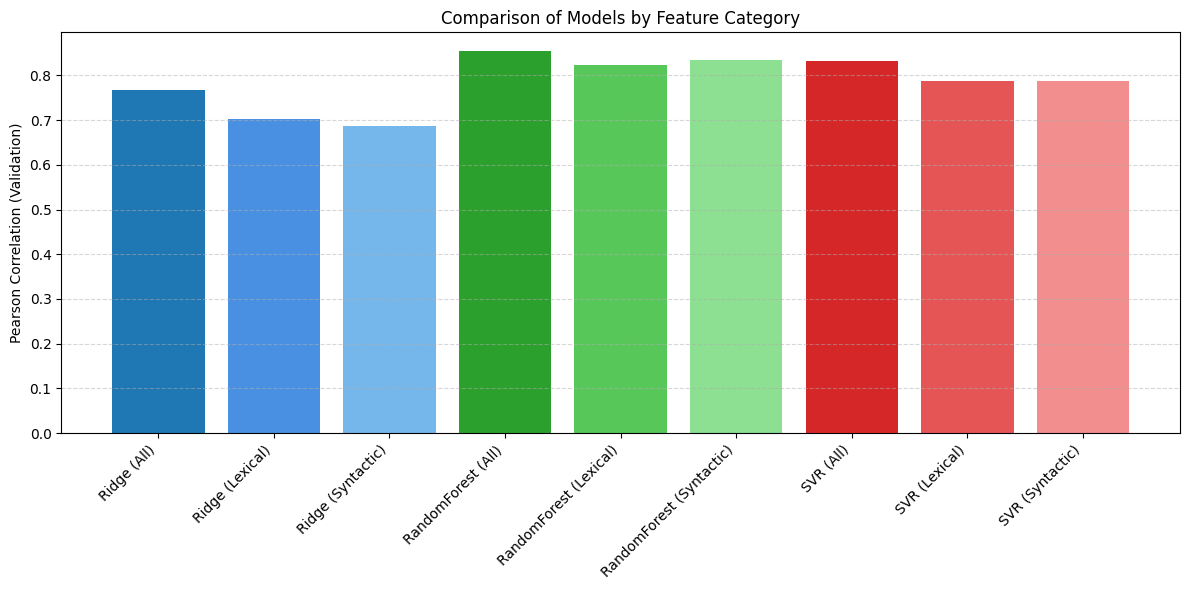

In [38]:
model_performance = {
    "Ridge (All)": corr_ridge_all,
    "Ridge (Lexical)": corr_ridge_lex,
    "Ridge (Syntactic)": corr_ridge_syn,

    "RandomForest (All)": corr_rf_all,
    "RandomForest (Lexical)": corr_rf_lex,
    "RandomForest (Syntactic)": corr_rf_syn,

    "SVR (All)": corr_svr_all,
    "SVR (Lexical)": corr_svr_lex,
    "SVR (Syntactic)": corr_svr_syn,
}

color_map = {
    "Ridge (All)":        "#1f77b4",
    "Ridge (Lexical)":    "#4a90e2",
    "Ridge (Syntactic)":  "#76b7eb",
    "Ridge (Filtered)":  "#240B7FF0", # for later

    "RandomForest (All)":       "#2ca02c",
    "RandomForest (Lexical)":   "#58c75a",
    "RandomForest (Syntactic)": "#8ddf91",
    "RandomForest (Filtered)": "#0ee419",  # for later

    "SVR (All)":        "#d62728",
    "SVR (Lexical)":    "#e65555",
    "SVR (Syntactic)":  "#f28e8e",
    "SVR (Filtered)":     "#751212",  # for later

}

labels = list(model_performance.keys())
scores = list(model_performance.values())
colors = [color_map[label] for label in labels]

plt.figure(figsize=(12, 6))
plt.bar(labels, scores, color=colors)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Pearson Correlation (Validation)")
plt.title("Comparison of Models by Feature Category")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


COMMENT THE PLOT

## 4) Feature selection



As we saw in the previous section,  not all of features contribute equally to the prediction. Some may be redundant, some may introduce noise, and some simply do not generalize well beyond the training folds. Eliminating such features often improves robustness, reduces overfitting, and helps interpretability.

To achieve this, we pursued a **two-step feature-selection strategy**:

---

### **(1) Backward Feature Elimination**

We applied our custom **backward elimination** procedure to each of the three main model families:

* **Ridge regression** (sensitive to collinearity, good for coefficient interpretation)
* **Random Forest regression** (tree-based, robust to non-linear interactions)
* **SVR** (strong general baseline, often stable with small feature sets)

Backward elimination iteratively removes features and evaluates whether this removal improves (or does not harm) the validation Pearson correlation. Since each model has different learning biases, this process highlights **model-specific redundancies** and gives a richer picture of which features are consistently useful.

### **(2) Cross-checking with Correlation and Feature Importance**

In addition to backward elimination, we also:

* Inspected the **correlation matrix** of features
* Analyzed model-based importance:

  * Ridge coefficients
  * RandomForest permutation importances

These three signals (correlations, importance scores, backward elimination) converge to reveal:

* **Highly redundant features**
* **Features that degrade performance**
* **Features essential across all models**

This hybrid approach allows us to justify feature-removal decisions rigorously and transparently.


In [14]:

print("\n===== BACKWARD ELIMINATION: RIDGE REGRESSION =====\n")


ridge_results = fs.backward_elimination(
    X_train, y_train,
    param_grid=ridge_param_grid,
    X_val=X_val, y_val=y_val,
    base_model=Ridge(random_state=42),
    
    verbose=1
)


print("\n===== BACKWARD ELIMINATION: RANDOM FOREST =====\n")

rf_results = fs.backward_elimination(
    X_train, y_train,
    param_grid=rf_param_grid,
    X_val=X_val, y_val=y_val,
    base_model=RandomForestRegressor(random_state=42),
    
    verbose=1
)

print("\n===== BACKWARD ELIMINATION: SVR =====\n")

svr_results = fs.backward_elimination(
    X_train, y_train,
    param_grid=svr_param_grid,
    X_val=X_val, y_val=y_val,
    base_model=SVR(),
    
    verbose=1
)



===== BACKWARD ELIMINATION: RIDGE REGRESSION =====

['word_jaccard_distance', 'compute_number_similarity', 'date_similarity', 'word_bigram_jaccard', 'word_trigram_jaccard', 'synset_jaccard_distance', 'weighted_wordnet_similarity', 'sentence_path_similarity', 'sentence_lch_similarity', 'sentence_wup_similarity', 'sentence_lin_similarity', 'sentence_path_similarity_max', 'sentence_lch_similarity_max', 'sentence_wup_similarity_max', 'sentence_lin_similarity_max', 'sentence_rarity_similarity', 'stem_jaccard_distance', 'lemma_jaccard_distance', 'lemma_bigram_jaccard', 'lemma_trigram_jaccard', 'pos_jaccard_distance', 'sentence_length_difference', 'longest_common_subsequence', 'longest_common_substring', 'greedy_string_tiling', 'pos_lev_distance', 'dep_lev_distance', 'ner_jaccard', 'ner_presence']
Iteration 1 / 28
	Testing removal of feature word_jaccard_distance
	feature 1 / 29 
    R Score = 0.7602, 
	Testing removal of feature compute_number_similarity
	feature 2 / 29 
    R Score = 0.767

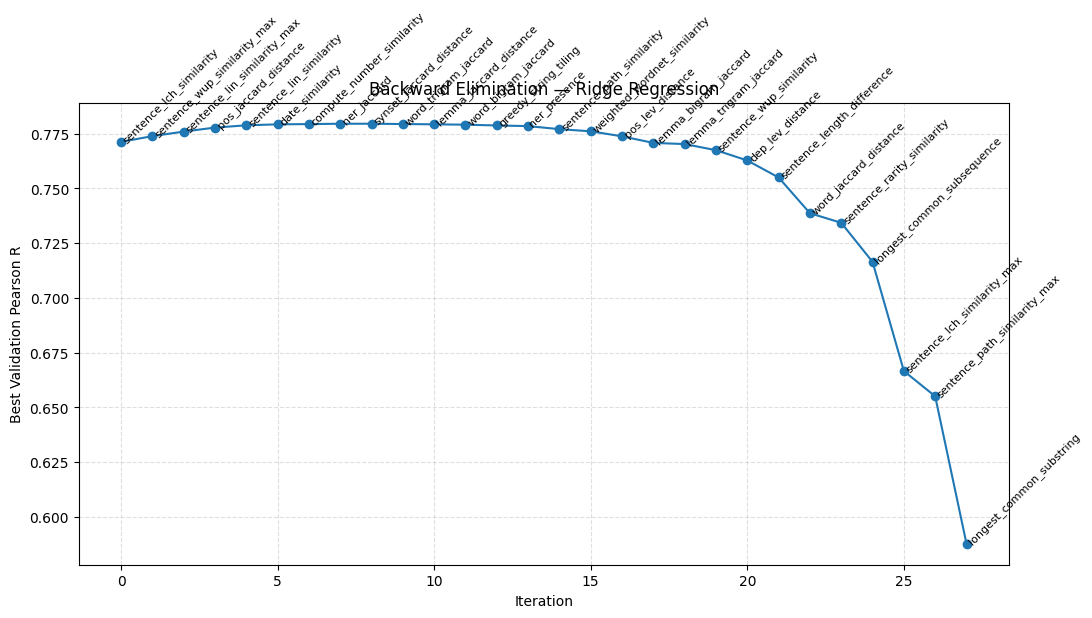

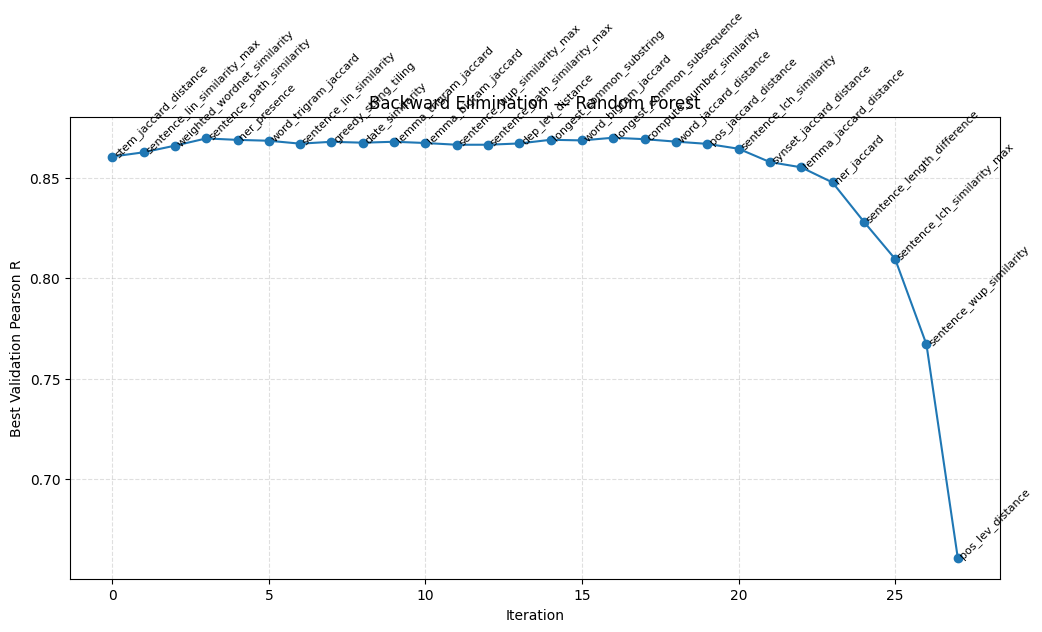

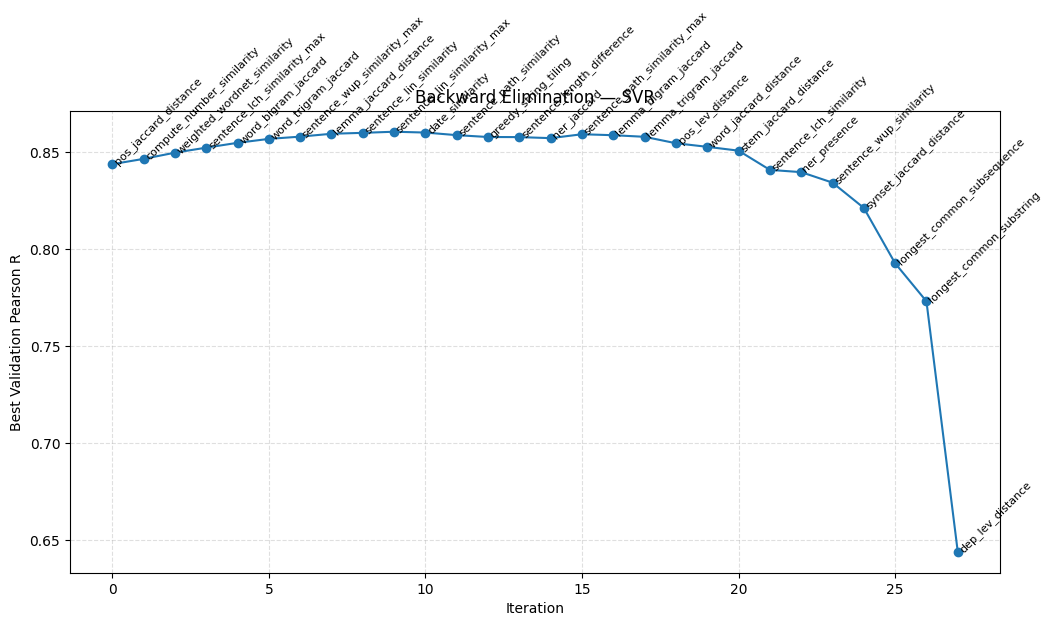

In [15]:
ridge_results = pd.read_csv("data/feature_selection/Ridge.csv")
rf_results =  pd.read_csv("data/feature_selection/RandomForestRegressor.csv")
svr_results =  pd.read_csv("data/feature_selection/SVR.csv")

fs.plot_elimination_history(ridge_results, "Backward Elimination — Ridge Regression")
fs.plot_elimination_history(rf_results, "Backward Elimination — Random Forest")
fs.plot_elimination_history(svr_results, "Backward Elimination — SVR")


A feature is considered redundant if removing it:

- improves the Pearson correlation, OR
- does not degrate it

Based on the above history and criterion, we identify the earliest removed featured (before the curve starts going down)

In [20]:
ridge_redundant = ridge_results.loc[:10, 'feature_removed']
rf_redundant = rf_results.loc[:15, 'feature_removed']
svr_redundant = svr_results.loc[:16, 'feature_removed']

redundant_union =  set(rf_redundant) | set(svr_redundant) #|set(ridge_redundant) 
redundant_intersection = set(rf_redundant) & set(svr_redundant) # & set(ridge_redundant) 


print("Union of the features identified as redundant across the two models:\n", len(redundant_union), redundant_union)
print("\nIntersection of the features identified as redundant across the two models:\n", len(redundant_intersection), redundant_intersection)

Union of the features identified as redundant across the two models:
 22 {'stem_jaccard_distance', 'lemma_bigram_jaccard', 'date_similarity', 'sentence_wup_similarity_max', 'word_bigram_jaccard', 'word_trigram_jaccard', 'sentence_lin_similarity_max', 'lemma_trigram_jaccard', 'longest_common_substring', 'dep_lev_distance', 'greedy_string_tiling', 'sentence_path_similarity_max', 'sentence_lin_similarity', 'sentence_path_similarity', 'compute_number_similarity', 'ner_jaccard', 'weighted_wordnet_similarity', 'lemma_jaccard_distance', 'sentence_lch_similarity_max', 'ner_presence', 'sentence_length_difference', 'pos_jaccard_distance'}

Intersection of the features identified as redundant across the two models:
 11 {'sentence_path_similarity', 'sentence_wup_similarity_max', 'lemma_bigram_jaccard', 'date_similarity', 'word_bigram_jaccard', 'word_trigram_jaccard', 'sentence_lin_similarity_max', 'weighted_wordnet_similarity', 'greedy_string_tiling', 'sentence_path_similarity_max', 'sentence_lin_

The backward-elimination experiments provided a practical way to measure how much each feature contributes to the predictive capability of the model. Because the procedure evaluates performance after removing each individual feature, it assigns an implicit ranking:
features removed early tend to be redundant or weakly informative, while features that survive until the final rounds typically carry the strongest predictive signal.

During this process, we intentionally focused on SVR and Random Forest as our primary decision models. Both can capture non-linear relationships and complex interactions among features, and our earlier results showed that they outperform linear models on this dataset.
For this reason, we did not rely on Ridge Regression for the elimination criteria, its linear structure limits its ability to exploit non-linear patterns in the data, making its elimination ordering less reliable for this particular prediction task.

### 6) Cross-Model Feature Interpretation

In this section, we bring together all the interpretability tools available to us to form a coherent picture of why certain features were removed and how the remaining ones contribute to prediction quality.

The goal here is not only to justify the feature-selection decisions, but also to understand the *mechanistic reasons* behind them:
which features overlap strongly with others, which introduce noise, and which provide core signal that generalizes across models.

To develop this deeper interpretation, we use three complementary sources of evidence:

 **(1) Ridge Regression Coefficients**

Although the linear model underperforms compared to SVR and Random Forest, it remains useful because its coefficients provide:

* a signed magnitude for every feature,
* an interpretable sense of whether the feature contributes positively or negatively,
* an implicit measure of redundancy (e.g., tiny coefficients often correspond to features already explained by others).

This helps verify whether the features eliminated early by backward elimination also appear weak or redundant in a linear framework.


In [17]:
df_coef = pd.DataFrame(best_ridge_all.coef_, index=X_train.columns, columns=["coef"])
df_coef.coef = abs(df_coef) 
df_coef.coef.sort_values()

compute_number_similarity       0.001715
synset_jaccard_distance         0.009330
greedy_string_tiling            0.033683
ner_presence                    0.077261
word_trigram_jaccard            0.092096
sentence_wup_similarity_max     0.147135
pos_jaccard_distance            0.160103
ner_jaccard                     0.179577
date_similarity                 0.211695
word_bigram_jaccard             0.222761
sentence_lin_similarity_max     0.461523
sentence_lch_similarity_max     0.574995
lemma_jaccard_distance          0.627235
sentence_path_similarity        0.630216
sentence_length_difference      0.644656
lemma_bigram_jaccard            0.809228
lemma_trigram_jaccard           1.032972
longest_common_subsequence      1.059129
sentence_path_similarity_max    1.444410
sentence_wup_similarity         1.558761
weighted_wordnet_similarity     1.614849
pos_lev_distance                1.780684
longest_common_substring        1.786451
sentence_lin_similarity         1.922278
sentence_rarity_



**(2) Random Forest Permutation Importance**

Permutation importance offers a non-linear estimate of how much each feature influences predictions.
If shuffling a feature barely changes model accuracy, the model considers it uninformative or redundant.

Comparing permutation importance to the elimination sequence helps confirm which features genuinely lack predictive strength.


In [19]:
from sklearn.inspection import permutation_importance

result = permutation_importance(best_rf_all, X_val, y_val, n_repeats=10)
importances = result.importances_mean
importances = pd.DataFrame(importances, index=X_train.columns, columns=["imp"])
importances.imp.sort_values()


date_similarity                 0.000008
lemma_trigram_jaccard           0.000285
compute_number_similarity       0.000394
pos_jaccard_distance            0.000820
word_trigram_jaccard            0.001250
ner_presence                    0.001563
lemma_jaccard_distance          0.001811
lemma_bigram_jaccard            0.002604
sentence_lch_similarity_max     0.002997
word_jaccard_distance           0.003865
longest_common_subsequence      0.004346
sentence_lch_similarity         0.004795
word_bigram_jaccard             0.004970
sentence_path_similarity_max    0.005563
sentence_lin_similarity         0.005779
sentence_lin_similarity_max     0.006765
weighted_wordnet_similarity     0.007243
greedy_string_tiling            0.008104
ner_jaccard                     0.017258
sentence_wup_similarity_max     0.019765
sentence_path_similarity        0.024887
synset_jaccard_distance         0.026061
sentence_length_difference      0.029608
sentence_wup_similarity         0.030115
pos_lev_distance

 **(3) Feature Correlation Matrix**

Many features may encode similar information.
Highly correlated features can:

* provide redundant signal,
* inflate coefficient variance in linear models,
* mislead feature-importance metrics.

Examining the correlation matrix helps identify clusters of interchangeable features and explains why some were removed without loss of accuracy.

In [20]:
X.corr()

,word_jaccard_distance,compute_number_similarity,date_similarity,word_bigram_jaccard,word_trigram_jaccard,synset_jaccard_distance,weighted_wordnet_similarity,sentence_path_similarity,sentence_lch_similarity,sentence_wup_similarity,...,lemma_trigram_jaccard,pos_jaccard_distance,sentence_length_difference,longest_common_subsequence,longest_common_substring,greedy_string_tiling,pos_lev_distance,dep_lev_distance,ner_jaccard,ner_presence
word_jaccard_distance,1.000000,-0.198677,-0.044024,-0.772098,-0.583323,0.744935,-0.966313,-0.682958,-0.309073,-0.467623,...,-0.492134,0.199511,0.083395,-0.566404,-0.388606,-0.610157,-0.086063,-0.080933,-0.045123,-0.315770
compute_number_similarity,-0.198677,1.000000,0.219706,0.118275,0.091789,-0.101855,0.189447,0.077701,-0.027479,0.003963,...,0.043166,-0.018954,-0.019506,0.048174,-0.090203,0.107353,0.247867,0.234187,0.030123,0.345439
date_similarity,-0.044024,0.219706,1.000000,0.036009,0.020436,-0.017879,0.034386,0.018418,0.003469,0.009300,...,-0.001137,-0.023419,-0.018919,0.051673,-0.053344,0.052216,0.074404,0.059298,0.014381,0.079299
word_bigram_jaccard,-0.772098,0.118275,0.036009,1.000000,0.816778,-0.595610,0.744113,0.450179,0.180134,0.289736,...,0.574820,-0.169723,-0.061378,0.441812,0.327983,0.456360,-0.000793,-0.004870,0.029054,0.207025
word_trigram_jaccard,-0.583323,0.091789,0.020436,0.816778,1.000000,-0.444482,0.563851,0.319987,0.117165,0.208139,...,0.621703,-0.132235,-0.057995,0.336841,0.256760,0.353854,-0.010336,-0.012640,0.010411,0.158271
synset_jaccard_distance,0.744935,-0.101855,-0.017879,-0.595610,-0.444482,1.000000,-0.703836,-0.638311,-0.347519,-0.460255,...,-0.480361,0.162373,0.147911,-0.579094,-0.441780,-0.554482,0.019558,0.024675,0.004147,-0.182570
weighted_wordnet_similarity,-0.966313,0.189447,0.034386,0.744113,0.563851,-0.703836,1.000000,0.659627,0.292346,0.441561,...,0.470426,-0.181652,-0.069810,0.525552,0.339502,0.569156,0.105011,0.101075,0.023759,0.314397
sentence_path_similarity,-0.682958,0.077701,0.018418,0.450179,0.319987,-0.638311,0.659627,1.000000,0.759544,0.921762,...,0.402785,-0.154675,-0.144722,0.602958,0.417279,0.510204,-0.045497,-0.037708,-0.086397,0.034549
sentence_lch_similarity,-0.309073,-0.027479,0.003469,0.180134,0.117165,-0.347519,0.292346,0.759544,1.000000,0.832603,...,0.247156,-0.104151,-0.136096,0.456656,0.406438,0.288554,-0.304412,-0.293628,-0.194056,-0.253242
sentence_wup_similarity,-0.467623,0.003963,0.009300,0.289736,0.208139,-0.460255,0.441561,0.921762,0.832603,1.000000,...,0.283041,-0.153564,-0.156995,0.515200,0.358501,0.396719,-0.087783,-0.075906,-0.115840,-0.082365





 **6.2 Linking the Evidence Together**

For each feature removed, we will:

* check its coefficient magnitude in Ridge,
* check its permutation importance in Random Forest,
* observe its correlation with other features,
* relate all of the above to its position in the elimination ranking for SVR and RF.
* confirm the removal by training the model with the subset of features and checking the validation score

This triangulation gives us confidence in which features are truly redundant, and which might appear weak in one model but remain important in others. After analysis and trial and error, we devised the final list of remove features.

**Final List of Removed Features and Explanation**

WRITE LIST OF FEATURES

### Training final models
We now retrain the three models (Ridge, Random Forest, SVR) using the final set of selected features. Although model scores helped guide the feature selection process, we did not simply choose the subset with the highest validation score. Our final choice also relied on the qualitative analysis from the previous section, with the intention of improving generalization rather than overfitting to the validation set.

The three models are now trained again with the reduced feature set and their best hyperparameters. Their performance will serve as the final comparison.

In [21]:
to_remove = [
    'greedy_string_tiling', 'lemma_bigram_jaccard', 'pos_jaccard_distance',
    'sentence_lin_similarity_max','word_bigram_jaccard',# 'synset_jaccard_distance',
    'lemma_jaccard_distance', 'ner_presence', # 'ner_jaccard',
    'sentence_wup_similarity', 'sentence_lch_similarity',
    'sentence_lin_similarity', 'sentence_path_similarity']
X_train_filtered = X_train.drop(columns=to_remove)
X_val_filtered = X_val.drop(columns=to_remove)

# Ridge Regression
# ------------

ridge_gs.fit(X_train_filtered, y_train) # no need to create a new estimator. sklearn erases previous learning when we run fit
best_ridge_filtered = ridge_gs.best_estimator_
preds_ridge_filtered, corr_ridge_filtered = pearson_corr(best_ridge_filtered, X_val_filtered, y_val)

print("Ridge Best Params:", ridge_gs.best_params_)
print("Ridge Pearson Corr on Validation:", corr_ridge_filtered)

# Random Forest Regression
# -----------
rf_gs.fit(X_train_filtered, y_train)
best_rf_filtered = rf_gs.best_estimator_
preds_rf_filtered, corr_rf_filtered = pearson_corr(best_rf_filtered, X_val_filtered, y_val)

print("Random Forest Best Params:", rf_gs.best_params_)
print("Random Forest Pearson Corr on Validation:", corr_rf_filtered)


# Support Vector Regression (SVR)
# -------------------------------
svr_gs.fit(X_train_filtered, y_train)
best_svr_filtered = svr_gs.best_estimator_
preds_svr_filtered, corr_svr_filtered = pearson_corr(best_svr_filtered, X_val_filtered, y_val)

print("SVR Best Params:", svr_gs.best_params_)
print("SVR Pearson Corr on Validation:", corr_svr_filtered)


c:\Users\Lucie Dupin\miniconda3\envs\ihlt-env\lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Ridge Best Params: {'alpha': 0.1, 'fit_intercept': True, 'solver': 'svd'}
Ridge Pearson Corr on Validation: 0.7678831869825996
Random Forest Best Params: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Random Forest Pearson Corr on Validation: 0.8442307229860939
SVR Best Params: {'C': 10, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}
SVR Pearson Corr on Validation: 0.8455362827932296


In [19]:
# CELL TO REMOVE BEFORE SUBMIT
objective_value = 0.7562

# ---- 5. Predict using best model ----
y_pred_new = best_rf_filtered.predict(X_test_scaled.drop(columns=to_remove))
#y_pred_new = regressor.predict(X_test_new_scaled)

# ---- 6. Evaluate ----
corr_new = np.corrcoef(y_test, y_pred_new)[0, 1]
print("Correlation on new STS test data:", corr_new)
if corr_new >= objective_value :
    print("goal achieved! Objective value exceeded by", abs(objective_value - corr_new))
else:
    print("Difference from objective value:", abs(objective_value - corr_new))


# ---- 5. Predict using best model ----
y_pred_new = best_svr_filtered.predict(X_test_scaled.drop(columns=to_remove))
#y_pred_new = regressor.predict(X_test_new_scaled)

# ---- 6. Evaluate ----
corr_new = np.corrcoef(y_test_new, y_pred_new)[0, 1]
print("Correlation on new STS test data:", corr_new)
if corr_new >= objective_value :
    print("goal achieved! Objective value exceeded by", abs(objective_value - corr_new))
else:
    print("Difference from objective value:", abs(objective_value - corr_new))

NameError: name 'X_test_scaled' is not defined

Correlation on train set: 0.8508324180411282

## Tests on test set

After selecting the model and the features, we mimic the submission process of Sem-Eval 2012 by 
- loading the provided test set
- applying preprocessing
- computing the features for hte test set
- normalizaing
- applying inference on the provided test set with the selected models

In [22]:
input_paths = [
    'data/test-gold/test-gold/STS.input.MSRpar.txt',
    'data/test-gold/test-gold/STS.input.MSRvid.txt',
    'data/test-gold/test-gold/STS.input.SMTeuroparl.txt',
    'data/test-gold/test-gold/STS.input.surprise.OnWN.txt',
    'data/test-gold/test-gold/STS.input.surprise.SMTnews.txt'
]

gold_paths = [
    'data/test-gold/test-gold/STS.gs.MSRpar.txt',
    'data/test-gold/test-gold/STS.gs.MSRvid.txt',
    'data/test-gold/test-gold/STS.gs.SMTeuroparl.txt',
    'data/test-gold/test-gold/STS.gs.surprise.OnWN.txt',
    'data/test-gold/test-gold/STS.gs.surprise.SMTnews.txt'
]

# Load all datasets
datasets = [
    load_files(gold_paths[i], input_paths[i])
    for i in range(len(input_paths))
]

df_test = merge_datasets(datasets)

df_test_preprocessed = pp.preprocess_dataframe(df_test)
#df_test_preprocessed.head(15)

Replacements were made:
Before: General Myers told reporters that "at first blush, it doesn't look like any rules were broken".
After:  General Myers told reporters that "at first blush, it doesn not look like any rules were broken".
Replacements were made:
Before: "At first blush, it doesn't look like any rules were broken," said Gen. Richard Myers, chairman of the Joint Chiefs of Staff.
After:  "At first blush, it doesn not look like any rules were broken," said Gen. Richard Myers, chairman of the Joint Chiefs of Staff.
Replacements were made:
Before: Daniels said he doesn't know what Bush will have to say about him at tonight's $2,000 per person presidential fund raiser.
After:  Daniels said he doesn not know what Bush will have to say about him at tonight's $2,000 per person presidential fund raiser.
Replacements were made:
Before: Daniels said he doesn't know what Bush will say at tonight's $2,000 per person reception to raise funds for his presidential re election bid.
After:  Da

In [23]:
# ---- 1. Compute features on test data ----
X_test_raw = ft.compute_features(df_test_preprocessed,features, feature_dir='data/features_test')
y_test = df_test_preprocessed['score']
# ---- 2. Scale using the existing scaler ----
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_raw),
    columns=X.columns
)
# ---- 3. Ensure columns match the selected features of te training set ----
X_test_filtered = X_test_scaled[X_train_filtered.columns]
X_test_syntactic = X_test_scaled[syntactic_match_features_names]
X_test_lexical = X_test_scaled[lexical_match_features_names]

preparing spacy analysis...
Loading cached feature: data/features_test/word_jaccard_distance.csv
Loading cached feature: data/features_test/compute_number_similarity.csv
Loading cached feature: data/features_test/date_similarity.csv
Loading cached feature: data/features_test/word_bigram_jaccard.csv
Loading cached feature: data/features_test/word_trigram_jaccard.csv
Loading cached feature: data/features_test/synset_jaccard_distance.csv
Loading cached feature: data/features_test/weighted_wordnet_similarity.csv
Loading cached feature: data/features_test/sentence_path_similarity.csv
Loading cached feature: data/features_test/sentence_lch_similarity.csv
Loading cached feature: data/features_test/sentence_wup_similarity.csv
Loading cached feature: data/features_test/sentence_lin_similarity.csv
Loading cached feature: data/features_test/sentence_path_similarity_max.csv
Loading cached feature: data/features_test/sentence_lch_similarity_max.csv
Loading cached feature: data/features_test/sentenc

### Models evaluation
We now evaluate all twelve trained models on the held-out test set. This allows us to compare their generalization performance and verify whether the feature-filtered versions maintain or improve predictive accuracy. We compute the Pearson correlation between predictions and gold scores, then focus our visualization on the six most relevant models (the versions trained on all features and on the filtered feature set). Finally, we gather both validation and test scores into a table for easy comparison.

In [46]:
val_scores = {
    "SVR (Syntactic)": (corr_svr_syn),
    "SVR (Lexical)": corr_svr_lex,
    "SVR (Filtered)": corr_svr_filtered,
    "SVR (All)": corr_svr_all,

    "RandomForest (All)": corr_rf_all,
    "RandomForest (Filtered)": corr_rf_filtered,
    "RandomForest (Syntactic)": corr_rf_syn,
    "RandomForest (Lexical)": corr_rf_lex,

    "Ridge (All)": corr_ridge_all,
    "Ridge (Filtered)": corr_ridge_filtered,
    "Ridge (Lexical)": corr_ridge_lex,
    "Ridge (Syntactic)": corr_ridge_syn
}

test_scores = {
    "SVR (Syntactic)": pearson_corr(best_svr_syn, X_test_syntactic, y_test),
    "SVR (Lexical)": pearson_corr(best_svr_lex, X_test_lexical, y_test),
    "SVR (Filtered)": pearson_corr(best_svr_filtered, X_test_filtered, y_test),
    "SVR (All)": pearson_corr(best_svr_all, X_test_scaled, y_test),

    "RandomForest (All)": pearson_corr(best_rf_all, X_test_scaled, y_test),
    "RandomForest (Filtered)": pearson_corr(best_rf_filtered, X_test_filtered, y_test),
    "RandomForest (Syntactic)": pearson_corr(best_rf_syn, X_test_syntactic, y_test),
    "RandomForest (Lexical)": pearson_corr(best_rf_lex, X_test_lexical, y_test),

    "Ridge (All)": pearson_corr(best_ridge_all, X_test_scaled, y_test),
    "Ridge (Filtered)": pearson_corr(best_ridge_filtered, X_test_filtered, y_test),
    "Ridge (Lexical)": pearson_corr(best_ridge_lex, X_test_lexical, y_test),
    "Ridge (Syntactic)": pearson_corr(best_ridge_syn, X_test_syntactic, y_test)
}


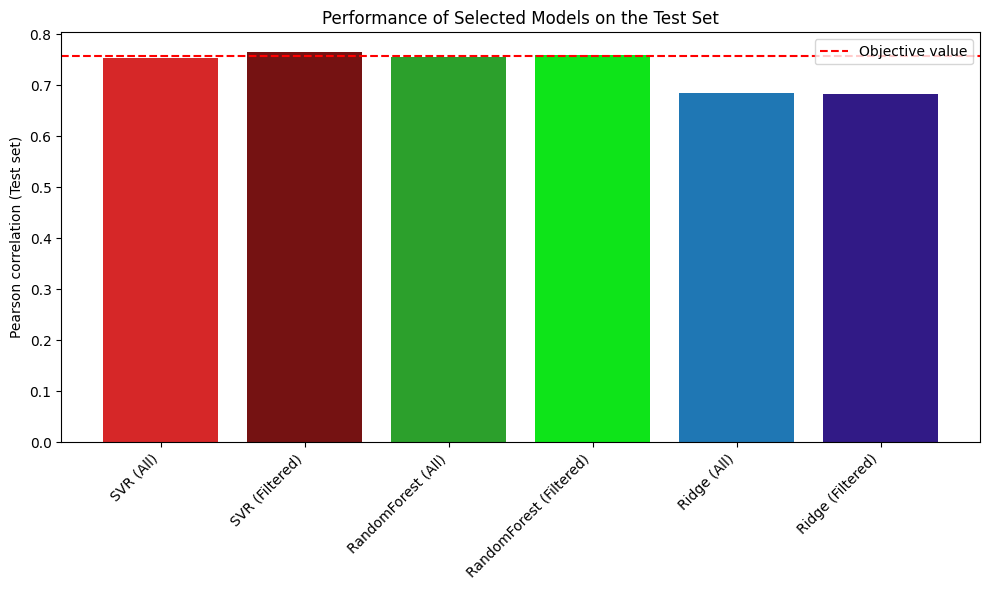

In [47]:
objective_value = 0.7562

relevant_models = [
    "SVR (All)", "SVR (Filtered)",
    "RandomForest (All)", "RandomForest (Filtered)",
    "Ridge (All)", "Ridge (Filtered)"
]

relevant_scores = [test_scores[m][1] for m in relevant_models]
colors = [color_map[m] for m in relevant_models]

plt.figure(figsize=(10, 6))
bars = plt.bar(relevant_models, relevant_scores, color=colors)

plt.axhline(objective_value, color="red", linestyle="--", label="Objective value")

plt.xticks(rotation=45, ha="right")
plt.ylabel("Pearson correlation (Test set)")
plt.title("Performance of Selected Models on the Test Set")
plt.legend()
plt.tight_layout()
plt.show()

In [48]:
df_scores = pd.DataFrame({
    "Model": list(test_scores.keys()),
    "Validation Pearson": [val_scores[m] for m in test_scores.keys()],
    "Test Pearson": [test_scores[m][1] for m in test_scores.keys()]
})
df_scores


,Model,Validation Pearson,Test Pearson
0,SVR (Syntactic),0.788537,0.661081
1,SVR (Lexical),0.788627,0.725993
2,SVR (Filtered),0.845536,0.765032
3,SVR (All),0.833350,0.753438
4,RandomForest (All),0.853702,0.755243
5,RandomForest (Filtered),0.844231,0.758752
6,RandomForest (Syntactic),0.835281,0.679504
7,RandomForest (Lexical),0.823705,0.729511
8,Ridge (All),0.767170,0.683858
9,Ridge (Filtered),0.767883,0.682531


COMMENT RESULTS

## Development process and Discussion

Below we analyze the predictions with high error to see where our model still struggles and why.
also talk abouthow we did to develop the features (papers, manual analysis...)

In [29]:
pred_best_model = test_scores['SVR (Filtered)'][1]

In [30]:

fs.identify_bad_predictions( df_test_preprocessed, pred_best_model, threshold=2).head(30)

,true,pred,error,sent1,sent2
1559,5.0,0.765032,4.234968,(Parliament adopted the legislative resolution),(Parliament adopted the legislative resolution)
3062,5.0,0.765032,4.234968,But the returns that make US stock markets so ...,But the returns that make us markets of securi...
1558,5.0,0.765032,4.234968,It is our job to continue to support Latvia wi...,It is our duty to continue to support Latvia o...
3061,5.0,0.765032,4.234968,Iraq's future depends directly on the fate of ...,Iraq's future is linked to oil production of t...
3082,5.0,0.765032,4.234968,Ahmadinejad is embarking on an adventure; Bern...,"Ahmadinejad are embarking on an adventure, not..."
3100,5.0,0.765032,4.234968,But they were necessary.,But they were necessary.
3075,5.0,0.765032,4.234968,The People Versus Putin,The people against Putin
3093,5.0,0.765032,4.234968,Iraq's future depends directly on the fate of ...,The future of Iraq is linked to the oil produc...
3095,5.0,0.765032,4.234968,What we are witnessing today is a shift from a...,We are witnessing today to change a Muslim ide...
3079,5.0,0.765032,4.234968,"But from the American point of view, the inter...","But the US point of view, the international ro..."


## Conclusion
blahblah